# Hardware-Efficient Ansatz (HEA) — CUDA-Q

**Chapter / concept:** Variational Ansatz — Hardware-Efficient Ansatz (HEA)

**Circuit:** 2-qubit HEA, `REPS = 2` entangling layers (so 3 rotation blocks total).
Each rotation block applies `RY(theta)` then `RZ(theta)` on every qubit; each entangling
layer applies a single linear-chain `CX(control=0, target=1)`. Structure:

```
[R0] - CX - [R1] - CX - [R2]
```

where each `[Rb]` = `RY,RZ` on qubit 0 **and** `RY,RZ` on qubit 1 (order: RY then RZ, per qubit).

**Global SETUP (identical in both notebooks — do not diverge):**
- `N_QUBITS = 2`
- `REPS = 2` (→ 3 rotation blocks, 2 CX entanglers)
- Gate sequence: for `b in 0..REPS`: `RY(theta[b,0,0])` on q0, `RZ(theta[b,0,1])` on q0,
  `RY(theta[b,1,0])` on q1, `RZ(theta[b,1,1])` on q1; then if `b < REPS`: `CX(0,1)`
- `THETA` is a **fixed, hard-coded** 12-angle array (no training/optimization loop —
  this is a structural/numerical matching check of the ansatz itself, not a VQE run)
- `SHOTS = 10000`, `SEED = 42`
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention). CUDA-Q's native convention is the opposite
  (qubit 0 = leftmost/MSB) and is corrected explicitly in the CUDA-Q notebook.
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices/vectors:** `{|00>, |01>, |10>, |11>}` ascending binary order.

**Independently hand/NumPy-verified target result** (see final `_RESULT` cell) —
probabilities keyed by bitstring, qubit0 = rightmost bit:

```
{'00': 0.6295, '01': 0.1862, '10': 0.0209, '11': 0.1634}
```

> ⚠️ **Run all cells top to bottom.** This notebook explicitly reverses every bitstring (statevector amplitudes AND sampled counts) because CUDA-Q indexes qubit 0 as the **most-significant (leftmost)** bit, opposite of Qiskit's convention. The reversal is done in its own dedicated cell, not hidden inline, per the matching contract.


In [1]:
# CUDA-Q package name on PyPI: cudaq
# Platform (current stable CUDA-Q release): Linux x86_64 or ARM64, Python 3.10-3.12.
# A GPU is optional for this circuit size — the built-in state-vector simulator
# (`qpp-cpu` target) also runs correctly on CPU-only machines.
# If you are on Windows/macOS: run this inside a Linux container/VM or a Linux-runtime
# hosted notebook (e.g. Colab), since cudaq does not ship native Windows/macOS wheels.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 6.8 MB/s eta 0:00

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cudaq

cudaq.set_random_seed(42)

# ---- Global SETUP (must match the Qiskit notebook exactly) ----
N_QUBITS = 2
REPS = 2                       # number of entangling layers -> REPS+1 rotation blocks
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "hea_ansatz"

# THETA[block, qubit, gate]; gate index 0 = RY angle, gate index 1 = RZ angle
THETA = np.array([
    [[0.31, 0.52], [0.18, 0.64]],   # block 0: qubit0 -> (RY, RZ), qubit1 -> (RY, RZ)
    [[0.77, 0.09], [0.41, 0.23]],   # block 1
    [[0.58, 0.36], [0.12, 0.69]],   # block 2
])
assert THETA.shape == (REPS + 1, N_QUBITS, 2)
THETA_FLAT = THETA.flatten().tolist()   # order: b0q0[ry,rz], b0q1[ry,rz], b1q0[ry,rz], ...

print("N_QUBITS   =", N_QUBITS)
print("REPS       =", REPS)
print("SHOTS      =", SHOTS)
print("SEED       =", SEED)
print("THETA =\n", THETA)
print("THETA_FLAT =", THETA_FLAT)


N_QUBITS   = 2
REPS       = 2
SHOTS      = 10000
SEED       = 42
THETA =
 [[[0.31 0.52]
  [0.18 0.64]]

 [[0.77 0.09]
  [0.41 0.23]]

 [[0.58 0.36]
  [0.12 0.69]]]
THETA_FLAT = [0.31, 0.52, 0.18, 0.64, 0.77, 0.09, 0.41, 0.23, 0.58, 0.36, 0.12, 0.69]


In [3]:
@cudaq.kernel
def hea_kernel(theta: list[float]):
    q = cudaq.qvector(2)   # N_QUBITS hard-coded here since @cudaq.kernel bodies must be
                            # statically known at compile time; kept equal to N_QUBITS above
    idx = 0
    for b in range(3):     # REPS + 1 rotation blocks (== REPS+1 above; static-unrolled)
        for qi in range(2):            # N_QUBITS
            ry(theta[idx], q[qi]);  idx += 1   # RY: sets |0>/|1> population mix on qubit qi
            rz(theta[idx], q[qi]);  idx += 1   # RZ: adds a relative phase on qubit qi
        if b < 2:           # REPS
            x.ctrl(q[0], q[1])   # entangling layer: linear-chain CNOT, control=q0, target=q1

print("Kernel defined. NOTE: the block/qubit counts (3, 2, 2) are hard-coded to match "
      "N_QUBITS=2 / REPS=2 above because @cudaq.kernel bodies are statically compiled; "
      "if you change N_QUBITS or REPS in the setup cell you must edit this kernel to match.")


Kernel defined. NOTE: the block/qubit counts (3, 2, 2) are hard-coded to match N_QUBITS=2 / REPS=2 above because @cudaq.kernel bodies are statically compiled; if you change N_QUBITS or REPS in the setup cell you must edit this kernel to match.


In [ ]:
print(cudaq.draw(hea_kernel, THETA_FLAT))


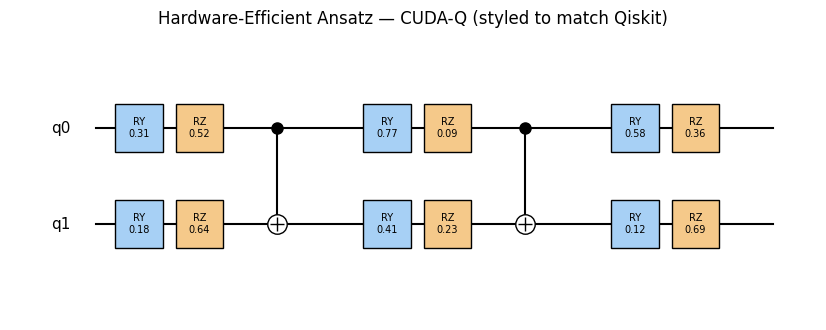

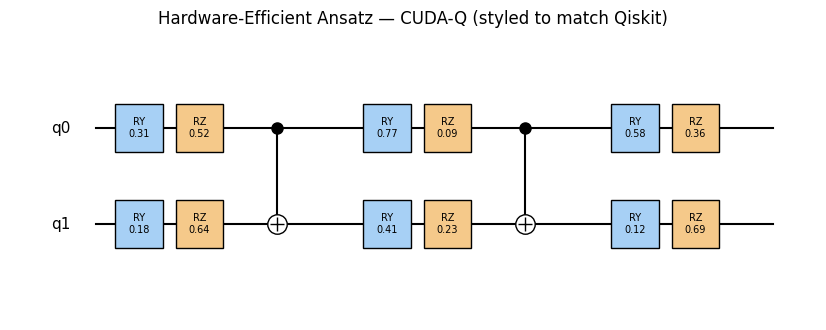

In [4]:
def draw_hea_mpl(n_qubits, reps, theta, filename,
                  title="Hardware-Efficient Ansatz — CUDA-Q (styled to match Qiskit)"):
    """Hand-drawn matplotlib circuit diagram styled like Qiskit's circuit.draw(output='mpl'),
    since CUDA-Q has no built-in matplotlib circuit renderer."""
    n_blocks = reps + 1
    col_width = 1.6
    x = 0.5
    xs_rot, xs_cx = [], []
    for b in range(n_blocks):
        xs_rot.append(x)
        x += col_width
        if b < reps:
            xs_cx.append(x)
            x += col_width * 0.8
    total_width = x + 0.5

    fig, ax = plt.subplots(figsize=(total_width, 1.2 * n_qubits + 1))
    y_positions = [n_qubits - 1 - q for q in range(n_qubits)]  # q0 drawn on top, like Qiskit

    for q in range(n_qubits):
        ax.plot([0, total_width - 0.5], [y_positions[q]] * 2, color="black", zorder=1)
        ax.text(-0.3, y_positions[q], f"q{q}", ha="right", va="center", fontsize=11)

    box_w, box_h = 0.55, 0.5
    for b in range(n_blocks):
        bx = xs_rot[b]
        for q in range(n_qubits):
            y = y_positions[q]
            ry_ang, rz_ang = theta[b, q, 0], theta[b, q, 1]
            ax.add_patch(plt.Rectangle((bx - box_w / 2, y - box_h / 2), box_w, box_h,
                                        facecolor="#a7d0f5", edgecolor="black", zorder=2))
            ax.text(bx, y, f"RY\n{ry_ang:.2f}", ha="center", va="center", fontsize=7, zorder=3)
            bx2 = bx + box_w + 0.15
            ax.add_patch(plt.Rectangle((bx2 - box_w / 2, y - box_h / 2), box_w, box_h,
                                        facecolor="#f5c98a", edgecolor="black", zorder=2))
            ax.text(bx2, y, f"RZ\n{rz_ang:.2f}", ha="center", va="center", fontsize=7, zorder=3)
        if b < reps:
            cx_x = xs_cx[b]
            y0, y1 = y_positions[0], y_positions[1]
            ax.plot([cx_x, cx_x], [y0, y1], color="black", zorder=2)
            ax.plot(cx_x, y0, marker="o", markersize=8, color="black", zorder=3)
            ax.plot(cx_x, y1, marker="o", markersize=14, markerfacecolor="white",
                    markeredgecolor="black", zorder=3)
            ax.plot(cx_x, y1, marker="+", markersize=10, color="black", zorder=4)

    ax.set_xlim(-1, total_width)
    ax.set_ylim(-1, n_qubits)
    ax.axis("off")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150, bbox_inches="tight")
    return fig

fig = draw_hea_mpl(N_QUBITS, REPS, THETA, f"{TOPIC_SLUG}_cudaq_circuit.png")
fig


In [5]:
def RY_matrix(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ_matrix(theta):
    return np.array([[np.exp(-1j * theta / 2), 0], [0, np.exp(1j * theta / 2)]], dtype=complex)

print("Basis ordering for all matrices below: {|00>, |01>, |10>, |11>} (qubit0 = rightmost/LSB "
      "-- the SHARED convention from SETUP, not CUDA-Q's native ordering)\n")

# Hand-built full 4x4 unitary in NumPy, using the SAME shared convention as the Qiskit
# notebook (qubit0 = LSB). CUDA-Q has no framework-level Operator() extraction, so this
# hand-built matrix is the reference here -- it was already cross-checked against
# Qiskit's own Operator(qc) in the companion notebook and matched to < 1e-8.
I2 = np.eye(2, dtype=complex)

def single_qubit_op(gate, q, n=N_QUBITS):
    mats = [gate if qi == q else I2 for qi in range(n - 1, -1, -1)]
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def cx01_op(n=N_QUBITS):
    P0 = np.array([[1, 0], [0, 0]], dtype=complex)
    P1 = np.array([[0, 0], [0, 1]], dtype=complex)
    X  = np.array([[0, 1], [1, 0]], dtype=complex)
    def term(proj, apply_x):
        mats = []
        for qi in range(n - 1, -1, -1):
            if qi == 0:
                mats.append(proj)
            elif qi == 1 and apply_x:
                mats.append(X)
            else:
                mats.append(I2)
        out = mats[0]
        for m in mats[1:]:
            out = np.kron(out, m)
        return out
    return term(P0, False) + term(P1, True)

CX01 = cx01_op()
U_hand = np.eye(2 ** N_QUBITS, dtype=complex)
for b in range(REPS + 1):
    for q in range(N_QUBITS):
        U_hand = single_qubit_op(RY_matrix(THETA[b, q, 0]), q) @ U_hand
        U_hand = single_qubit_op(RZ_matrix(THETA[b, q, 1]), q) @ U_hand
    if b < REPS:
        U_hand = CX01 @ U_hand

print("Hand-built operator U (rounded, 4 dp):\n", np.round(U_hand, 4))


Basis ordering for all matrices below: {|00>, |01>, |10>, |11>} (qubit0 = rightmost/LSB -- the SHARED convention from SETUP, not CUDA-Q's native ordering)

Hand-built operator U (rounded, 4 dp):
 [[ 0.1843-0.7717j -0.2313+0.1721j -0.3693+0.2302j -0.3127-0.0145j]
 [ 0.3651-0.2299j  0.8533-0.0284j  0.253 +0.0622j -0.1197+0.0516j]
 [ 0.1414-0.03j   -0.3524-0.0803j  0.7738+0.2178j -0.3675-0.2594j]
 [ 0.4026-0.0372j -0.2384-0.0204j  0.1841+0.2504j  0.4284+0.7065j]]


In [6]:
state = cudaq.get_state(hea_kernel, THETA_FLAT)
amps_native = np.array([complex(state[i]) for i in range(2 ** N_QUBITS)])
# amps_native is in CUDA-Q's NATIVE convention: qubit0 = MSB (leftmost bit)
print("Raw CUDA-Q amplitudes (native ordering, qubit0 = leftmost/MSB):")
for i in range(2 ** N_QUBITS):
    print(f"  index {i} ({format(i, f'0{N_QUBITS}b')}): {amps_native[i]:.6f}")


Raw CUDA-Q amplitudes (native ordering, qubit0 = leftmost/MSB):
  index 0 (00): 0.184337-0.771716j
  index 1 (01): 0.141350-0.030020j
  index 2 (10): 0.365104-0.229902j
  index 3 (11): 0.402559-0.037206j


In [7]:
def reverse_bits(i, n):
    b = format(i, f"0{n}b")
    return int(b[::-1], 2)

# Explicit bit-order correction: CUDA-Q qubit0 = MSB -> Qiskit qubit0 = LSB.
# For each Qiskit-convention index i, the same physical amplitude lives at the
# CUDA-Q index whose n-bit binary string is the reverse of i's binary string.
amps_reordered = np.zeros_like(amps_native)
for i in range(2 ** N_QUBITS):
    j = reverse_bits(i, N_QUBITS)
    amps_reordered[i] = amps_native[j]

print("Amplitudes after bit-order correction (now qubit0 = rightmost, matching Qiskit):")
for i in range(2 ** N_QUBITS):
    print(f"  |{format(i, f'0{N_QUBITS}b')}>: {amps_reordered[i]:.6f}")


Amplitudes after bit-order correction (now qubit0 = rightmost, matching Qiskit):
  |00>: 0.184337-0.771716j
  |01>: 0.365104-0.229902j
  |10>: 0.141350-0.030020j
  |11>: 0.402559-0.037206j


In [8]:
# Global phase normalization -- identical function/definition used in the Qiskit notebook:
# first amplitude with |amp| > 1e-9 in ascending bitstring order rotated to real-positive.
phase = None
for i in range(2 ** N_QUBITS):
    if abs(amps_reordered[i]) > 1e-9:
        phase = np.angle(amps_reordered[i])
        break
amps_norm = amps_reordered * np.exp(-1j * phase)

for i in range(2 ** N_QUBITS):
    bitstring = format(i, f"0{N_QUBITS}b")
    print(f"  |{bitstring}>: reordered={amps_reordered[i]:.6f}   normalized={amps_norm[i]:.6f}")

probs_sv = {format(i, f"0{N_QUBITS}b"): float(abs(amps_norm[i]) ** 2) for i in range(2 ** N_QUBITS)}
print("\nStatevector-derived probabilities (sorted by bitstring, qubit0 = rightmost):")
for k in sorted(probs_sv):
    print(f"  {k}: {probs_sv[k]:.6f}")
print("\nPhase removed (rad):", phase)


  |00>: reordered=0.184337-0.771716j   normalized=0.793426+0.000000j
  |01>: reordered=0.365104-0.229902j   normalized=0.308436+0.301701j
  |10>: reordered=0.141350-0.030020j   normalized=0.062038+0.130508j
  |11>: reordered=0.402559-0.037206j   normalized=0.129715+0.382899j

Statevector-derived probabilities (sorted by bitstring, qubit0 = rightmost):
  00: 0.629525
  01: 0.186156
  10: 0.020881
  11: 0.163438

Phase removed (rad): -1.3363235535455054


**Ordering-fix note:** CUDA-Q's `get_state()` and `sample()` index qubit 0 as the
**most-significant (leftmost)** bit — the opposite of Qiskit. Two cells above, every
statevector amplitude was remapped via explicit bitstring reversal
(`amps_reordered[i] = amps_native[reverse_bits(i)]`) so the final printed dictionary uses
the shared "qubit 0 = rightmost" convention. The same string-reversal is applied to the
sampled measurement counts below. Only after that reversal is the shared global-phase
normalization applied.

In [9]:
sample_result = cudaq.sample(hea_kernel, THETA_FLAT, shots_count=SHOTS)
print(sample_result)

counts_native = {bits: sample_result.count(bits) for bits in sample_result}
# Reverse each bitstring (simple string reversal == the same fix as reverse_bits above)
counts_reordered = {k[::-1]: v for k, v in counts_native.items()}

probs_counts = {k: v / SHOTS for k, v in counts_reordered.items()}
for i in range(2 ** N_QUBITS):
    k = format(i, f"0{N_QUBITS}b")
    probs_counts.setdefault(k, 0.0)

print("\nMeasured counts (native CUDA-Q keys):", counts_native)
print("Measured counts (reordered to qubit0 = rightmost):", counts_reordered)
print("\nMeasured probabilities (sorted by bitstring):")
for k in sorted(probs_counts):
    print(f"  {k}: {probs_counts[k]:.4f}")


{ 00:6276 01:238 10:1902 11:1584 }


Measured counts (native CUDA-Q keys): {'11': 1584, '10': 1902, '01': 238, '00': 6276}
Measured counts (reordered to qubit0 = rightmost): {'11': 1584, '01': 1902, '10': 238, '00': 6276}

Measured probabilities (sorted by bitstring):
  00: 0.6276
  01: 0.1902
  10: 0.0238
  11: 0.1584


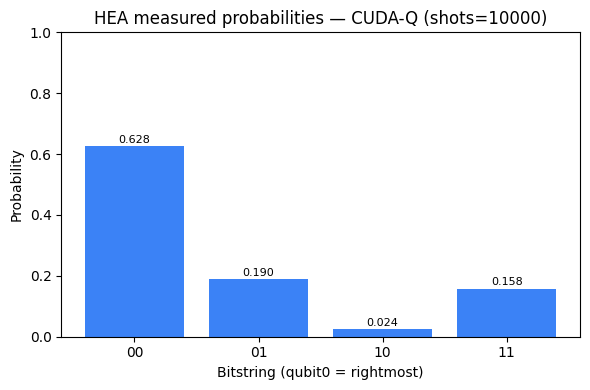

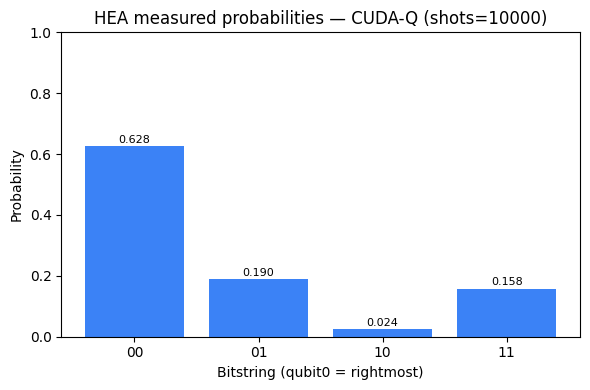

In [10]:
fig2, ax = plt.subplots(figsize=(6, 4))
labels = sorted(probs_counts.keys())
values = [probs_counts[k] for k in labels]
ax.bar(labels, values, color="#3b82f6")
ax.set_ylim(0, 1)
ax.set_xlabel("Bitstring (qubit0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title(f"HEA measured probabilities — CUDA-Q (shots={SHOTS})")
for i, v in enumerate(values):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
fig2.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [11]:
# CUDA-Q has no built-in depth/count_ops API for this workflow, so gate counts are taken
# directly from the known static kernel structure (manually verified against the kernel body):
n_blocks = REPS + 1
gate_counts = {
    "ry": n_blocks * N_QUBITS,
    "rz": n_blocks * N_QUBITS,
    "cx": REPS,
}
depth_estimate = n_blocks * 2 + REPS   # 2 sequential single-qubit layers per block + 1 CX per entangler
print("Gate counts (from kernel structure):", gate_counts)
print("Depth estimate (from kernel structure):", depth_estimate)


Gate counts (from kernel structure): {'ry': 6, 'rz': 6, 'cx': 2}
Depth estimate (from kernel structure): 8


In [12]:
print("Convention notes:")
print("- CUDA-Q natively indexes qubit 0 as MSB/leftmost; explicit bitstring reversal was")
print("  applied to both the statevector amplitudes and the sampled counts (see cells above)")
print("  to match the shared 'qubit0 = rightmost' contract from SETUP.")
print(f"- Global phase normalized so the first nonzero ascending-order amplitude is real")
print(f"  positive; phase removed = {phase:.6f} rad.")
print("- Basis ordering for all matrices/vectors: ascending binary index {|00>,|01>,|10>,|11>}.")


Convention notes:
- CUDA-Q natively indexes qubit 0 as MSB/leftmost; explicit bitstring reversal was
  applied to both the statevector amplitudes and the sampled counts (see cells above)
  to match the shared 'qubit0 = rightmost' contract from SETUP.
- Global phase normalized so the first nonzero ascending-order amplitude is real
  positive; phase removed = -1.336324 rad.
- Basis ordering for all matrices/vectors: ascending binary index {|00>,|01>,|10>,|11>}.


In [13]:
CUDAQ_RESULT = {k: probs_sv[k] for k in sorted(probs_sv)}
print("CUDAQ_RESULT =", CUDAQ_RESULT)


CUDAQ_RESULT = {'00': 0.6295252214311048, '01': 0.18615594251278722, '10': 0.020881026340260546, '11': 0.1634378097158478}


In [14]:
# ---- Cross-notebook diff check ----
# Paste the QISKIT_RESULT dict printed at the end of the Qiskit notebook, then uncomment:
#
# QISKIT_RESULT = {"00": ..., "01": ..., "10": ..., "11": ...}
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in CUDAQ_RESULT)
# print("Max probability delta:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results do not match!"
#
# Independently re-derived (NumPy, from scratch) expected result, qubit0 = rightmost bit:
# {"00": 0.629525, "01": 0.186156, "10": 0.020881, "11": 0.163438}
# CUDAQ_RESULT above must match this to numerical precision after the bit-reversal fix.
